# 11 - Four-Bucket Sort and Uplift@k

**Purpose:** Measure the realized uplift from targeting the model's top-ranked customers, sort test customers into Persuadable, Sure Thing, Lost Cause, and Sleeping Dog buckets, and check each bucket against realized outcomes.

**Inputs:** `../data/test.parquet`, `../models/winning_uplift_model.pkl`, `../models/winning_model_name.txt`, `../models/s_learner_base_estimator.pkl`.

**Outputs:** Uplift@k table, bucket sizes, and realized lift per bucket.

In [1]:
# ==========================================
# Load Model and Predict Uplift
# ==========================================
import warnings
warnings.filterwarnings('ignore', message='Function stable_cumsum is deprecated')
import numpy as np
import pandas as pd
import joblib

test_df = pd.read_parquet('../data/test.parquet')
feature_cols = [c for c in test_df.columns if c not in ['visit', 'treatment_flag', 'spend']]
X_test, y_test, t_test = test_df[feature_cols], test_df['visit'], test_df['treatment_flag']

with open('../models/winning_model_name.txt') as f:
    winner_name = f.read().strip()
winning_model = joblib.load('../models/winning_uplift_model.pkl')
winning_uplift = winning_model.predict(X_test)
print(winner_name, X_test.shape)

S-Learner (12808, 11)


In [2]:
# ==========================================
# Realized Uplift@k Evaluation
# ==========================================
from sklift.metrics import uplift_at_k

rows = []
for k in [0.1, 0.2, 0.3, 0.4, 0.5]:
    rows.append({'top_k_share': k, 'customers': int(len(y_test) * k),
                 'realized_uplift_pp': uplift_at_k(y_test, winning_uplift, t_test, strategy='overall', k=k) * 100})

# uplift_at_k only accepts 0 < k < 1, so the "target everyone" baseline is computed directly
overall = y_test[t_test == 1].mean() - y_test[t_test == 0].mean()
rows.append({'top_k_share': 1.0, 'customers': len(y_test), 'realized_uplift_pp': overall * 100})
print(pd.DataFrame(rows).round(2).to_string(index=False))

 top_k_share  customers  realized_uplift_pp
         0.1       1280                7.14
         0.2       2561                5.74
         0.3       3842                6.22
         0.4       5123                6.06
         0.5       6404                5.76
         1.0      12808                3.59


**Uplift@k.** Targeting only the model's top-ranked customers gives a higher realized uplift than emailing everyone. The top 10% show 7.14pp (n = 1,280), the top 20% 5.74pp, the top 30% 6.22pp, the top 40% 6.06pp and the top 50% 5.76pp, against 3.59pp for all 12,808 customers. So the model concentrates the campaign effect: the top half of customers show about 1.6 times the average lift. The values do not fall smoothly as k grows, and the top 10% rests on only about 640 customers per arm (a 95% interval of roughly ±4pp), so differences of a point or so between rows are noise. What the table supports is the overall pattern, consistent with the Qini curve in 10_model_evaluation: the model's ranking carries real signal, though it is far from perfect.

In [3]:
# ==========================================
# Counterfactual Response Probabilities
# ==========================================
if winner_name == 'T-Learner':
    treatment_model = joblib.load('../models/t_learner_treatment_arm.pkl')
    control_model = joblib.load('../models/t_learner_control_arm.pkl')
    p_treat = treatment_model.predict_proba(X_test)[:, 1]
    p_ctrl = control_model.predict_proba(X_test)[:, 1]
else:  # S-Learner
    solo_estimator = joblib.load('../models/s_learner_base_estimator.pkl')
    p_treat = solo_estimator.predict_proba(X_test.assign(treatment=1))[:, 1]
    p_ctrl = solo_estimator.predict_proba(X_test.assign(treatment=0))[:, 1]

print("Reproduces the model's own uplift:", np.allclose(p_treat - p_ctrl, winning_uplift, atol=1e-6))

Reproduces the model's own uplift: True


In [4]:
# ==========================================
# Four-Bucket Segmentation Sort
# ==========================================
p_treat_high = p_treat > np.median(p_treat)
p_ctrl_high = p_ctrl > np.median(p_ctrl)

bucket = np.select(
    [~p_ctrl_high & p_treat_high,    # Persuadable
     p_ctrl_high & p_treat_high,     # Sure Thing
     ~p_ctrl_high & ~p_treat_high,   # Lost Cause
     p_ctrl_high & ~p_treat_high],   # Sleeping Dog
    ['Persuadable', 'Sure Thing', 'Lost Cause', 'Sleeping Dog'],
    default='Unassigned'
)
assert (bucket != 'Unassigned').all()

Persuadable     11.9
Sure Thing      38.1
Lost Cause      38.1
Sleeping Dog    11.9


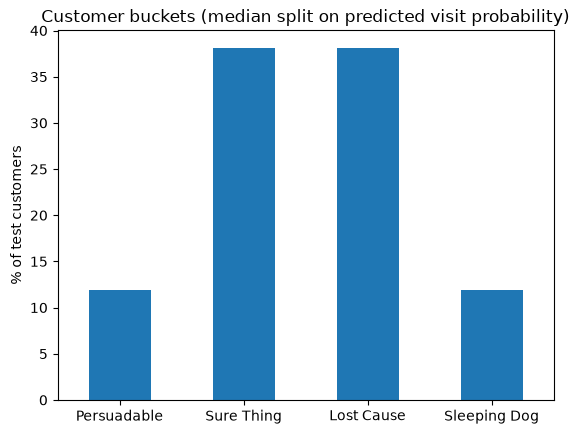

In [5]:
# ==========================================
# Bucket Sizes and Distribution
# ==========================================
import matplotlib.pyplot as plt

order = ['Persuadable', 'Sure Thing', 'Lost Cause', 'Sleeping Dog']
shares = pd.Series(bucket).value_counts(normalize=True).reindex(order) * 100
print(shares.round(1).to_string())

ax = shares.plot(kind='bar', rot=0)
ax.set_ylabel('% of test customers')
ax.set_title('Customer buckets (median split on predicted visit probability)')
plt.show()


In [6]:
# ==========================================
# Realized vs Predicted Lift per Bucket
# ==========================================
order = ['Persuadable', 'Sure Thing', 'Lost Cause', 'Sleeping Dog']
y_arr, t_arr = y_test.to_numpy(), t_test.to_numpy()
rows = []
for name in order:
    m = bucket == name
    yt, yc = y_arr[m & (t_arr == 1)], y_arr[m & (t_arr == 0)]
    lift = yt.mean() - yc.mean()
    se = np.sqrt(yt.var(ddof=1) / len(yt) + yc.var(ddof=1) / len(yc))
    rows.append({'bucket': name, 'customers': int(m.sum()),
                 'predicted_uplift_pp': (p_treat - p_ctrl)[m].mean() * 100,
                 'treated_visit_%': yt.mean() * 100, 'control_visit_%': yc.mean() * 100,
                 'realized_lift_pp': lift * 100,
                 'ci_low_pp': (lift - 1.96 * se) * 100, 'ci_high_pp': (lift + 1.96 * se) * 100})
print(pd.DataFrame(rows).round(2).to_string(index=False))

      bucket  customers  predicted_uplift_pp  treated_visit_%  control_visit_%  realized_lift_pp  ci_low_pp  ci_high_pp
 Persuadable       1522                11.81            13.70            10.56              3.13      -0.14        6.41
  Sure Thing       4882                 6.99            19.48            14.48              5.00       2.90        7.10
  Lost Cause       4882                 2.84             9.92             7.35              2.58       1.00        4.15
Sleeping Dog       1522                -2.11            15.03            11.97              3.06      -0.37        6.50


**Bucket validation.** The median split gives 11.9% Persuadable, 38.1% Sure Thing, 38.1% Lost Cause and 11.9% Sleeping Dog. Those sizes are set by the rule, so they say nothing about the customers. The realized lifts in the randomized test set are what count, and they do not support the labels:

- **Sleeping Dog.** The model predicts -2.11pp, but the realized lift is +3.06pp (95% CI -0.37 to 6.50). The interval rules out the predicted harm and does not show any harm at all. There is no evidence that the email drives any group away.
- **Persuadable.** The model predicts +11.81pp, but the realized lift is 3.13pp (95% CI -0.14 to 6.41), roughly a quarter of the prediction and no higher than the Sleeping Dog bucket.
- **Sure Thing and Lost Cause** come closer to their predictions (6.99 vs. 5.00pp and 2.84 vs. 2.58pp). Sure Thing shows the largest realized lift of the four, the opposite of the usual assumption that high-baseline customers add little. The gap to Lost Cause (5.00 vs. 2.58pp) is borderline at this sample size.

Persuadable and Sleeping Dog have the same realized lift (3.13 vs. 3.06pp), so the four buckets do not separate customers by how much the email helps them. Each bucket holds only about 1,500 to 4,900 customers, so the intervals are wide, and this shows the data cannot confirm the labels, not that the groups are identical. Buckets chosen for extreme predicted values also tend to overstate their effect, because noise helps put customers in the extreme tail. The practical conclusion is to use the model for ranking (uplift@k above, Qini in 10_model_evaluation) and not to trust the size of its predicted uplifts or the bucket labels.